# 07. 그 모델이 정말 최선일까? — 그리드 서치와 오토머신러닝으로 다시 확인하기

안녕하세요! **KBO 승패 예측 프로젝트의 일곱 번째 이야기**예요. 짝이 되는 코드는 `src/kbo_predict/automl.py`(오토머신러닝)와
`src/kbo_predict/tune.py`의 그리드 서치(`run_grid`)예요.

**이 노트북이 하는 일**
- 06번 노트북의 랜덤 서치는 탐색 범위에서 계열마다 40개 설정만 뽑아 봤어요. 그래서 "안 본 조합 중에 더 좋은 게 있지 않을까?"를 두 가지로 확인해요.
  1. **그리드 서치**: 같은 범위의 **모든 조합 3,602개**를 같은 교차검증으로 잽니다(`python -m kbo_predict.tune --grid`, 약 36분).
  2. **오토머신러닝(FLAML)**: 사람이 정한 범위 밖까지, 알고리즘과 설정을 함께 스스로 찾게 해요(`python -m kbo_predict.automl`, 20분 예산).
- 탐색 자체는 오래 걸려서 미리 돌려 두었고, 이 노트북은 결과 파일을 읽어 보여 줘요. **결승 단계는 여기서 다시 계산해서** 스크립트와 숫자가 같은지 확인해요.

**왜 이렇게 하나요?**
- "튜닝해 봤더니 이게 제일 좋았다"는 말은 **찾아본 범위 안에서만** 참이에요. 다른 방법으로 찾아도 비슷한 답이 나오면 그 결론을 더 믿을 수 있어요.
- 세 방법 모두 **2026 시즌(시험)은 고르는 데 한 번도 쓰지 않아요.** 고른 뒤에 채점만 해요. 그래야 시험 점수가 "처음 보는 시즌" 성적이 돼요.

> **읽기 전에 (2026-11 덧붙임):** 이 노트북에서 **"지금 모델"**은 이 튜닝을 할 때의 라이브 모델 **v0.2**(로지스틱 회귀 L2, C = 1, 피처 26개, Platt 보정)를 뜻해요. 분석 내용은 그대로 맞아요. 다만 그 뒤 08번 노트북의 **여러 시즌 시험**을 근거로 모델을 **v0.3**(로지스틱 회귀 L1, C = 0.03 + Elo 피처)으로 바꿨어요. 자세한 이야기는 맨 끝에 적어 뒀어요.

## 1. 준비

- 이 노트북은 `notebooks/` 폴더에서 실행되니까, 한 단계 위가 프로젝트 루트예요. `src/`를 파이썬 경로에 넣어요.
- 랜덤포레스트가 CPU 코어 수를 찾다 내는 안내 메시지를 막으려고 `LOKY_MAX_CPU_COUNT`를 먼저 정해요(결과에는 영향이 없어요).
- 결과 파일 세 개(랜덤 서치·그리드 서치·오토머신러닝)와 피처 표를 읽어요.

In [1]:
import json
import logging
import os
import sys
import time
import warnings
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")          # scikit-learn이 코어 수를 찾다 내는 경고를 막아요
warnings.filterwarnings("ignore")                          # 수렴·버전 안내 메시지는 숨겨요 (계산에는 영향 없음)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

T0 = time.time()
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

from kbo_predict import automl, tune
from kbo_predict.features import FEATURE_NAMES, load_features

plt.rcParams["font.family"] = ["Malgun Gothic", "AppleGothic", "NanumGothic", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)  # 없는 후보 폰트 안내 메시지는 숨겨요
pd.set_option("display.max_colwidth", 120)

PUBLIC = ROOT / "data" / "public"
df = load_features(ROOT / "data" / "processed" / "features.parquet")
random_rep = json.loads((PUBLIC / "tuning_report.json").read_text(encoding="utf-8"))
grid_rep = json.loads((PUBLIC / "tuning_grid_report.json").read_text(encoding="utf-8"))
auto_rep = json.loads((PUBLIC / "automl_report.json").read_text(encoding="utf-8"))
print(f"피처 표 {len(df):,}경기 × 피처 {len(FEATURE_NAMES)}개")
print("그리드 서치:", grid_rep["generated_at"], f"/ 설정 {sum(grid_rep['n_configs'].values()):,}개 / {grid_rep['elapsed_sec'] / 60:.0f}분")
print("오토머신러닝:", auto_rep["generated_at"], f"/ 시간 예산 {auto_rep['search']['time_budget_sec'] // 60}분")

피처 표 8,465경기 × 피처 26개
그리드 서치: 2026-11-03T09:15:28+09:00 / 설정 3,602개 / 36분
오토머신러닝: 2026-11-03T09:37:58+09:00 / 시간 예산 20분


## 2. 그리드 서치 — 랜덤 서치가 놓친 조합이 있었나

계열마다 교차검증(2021~2025 다섯 시즌, 약 3,500경기) log loss 1등을 비교해요. 낮을수록 좋아요.
"랜덤 1등의 그리드 순위"가 1위면 랜덤 서치가 이미 최선을 찾았다는 뜻이에요.

In [2]:
vs = pd.DataFrame([
    {"계열": tune.FAMILY_KO[f], "조합 수": grid_rep["n_configs"][f], "랜덤 서치 1등 CV": v["random_best_cv"],
     "그리드 1등 CV": v["grid_best_cv"], "랜덤 1등의 그리드 순위": v["grid_rank_of_random_best"], "같은 설정?": "예" if v["same_config"] else "아니오"}
    for f, v in grid_rep["vs_random_search"].items()
])
display(vs.style.format({"랜덤 서치 1등 CV": "{:.5f}", "그리드 1등 CV": "{:.5f}"}).hide(axis="index"))

계열,조합 수,랜덤 서치 1등 CV,그리드 1등 CV,랜덤 1등의 그리드 순위,같은 설정?
로지스틱 회귀,14,0.67930,0.67930,1,예
랜덤포레스트,120,0.67922,0.67896,2,아니오
엑스트라 트리,120,0.68076,0.68076,1,예
히스토그램 부스팅(sklearn),324,0.68098,0.68050,12,아니오
LightGBM,1296,0.68083,0.68014,42,아니오
XGBoost,1728,0.67961,0.67859,18,아니오


- 로지스틱 회귀와 엑스트라 트리는 랜덤 서치 1등이 그대로 그리드 1등이에요.
- 나머지 네 계열은 그리드가 조금 더 나은 설정을 찾았어요(LightGBM은 랜덤 1등이 그리드에서 42위). 다만 차이는 log loss 0.001 안팎이에요.

## 3. 그리드 결승 — 성적표와 같은 절차로 다시 계산

계열별 그리드 1등을 06번과 같은 결승 절차(2015~2024 학습 → 학습 시즌으로 확률 보정 → 2025 검증으로 고르기 → 2026 채점)에 넣어요.
여기서 다시 계산한 숫자가 결과 파일과 같은지 봐요. 랜덤포레스트는 나무 여러 개를 병렬로 더하는 순서 때문에 소수점 16번째 자리쯤이 달라질 수 있어서,
**10억분의 1 이내면 같다**고 봐요.

In [3]:
rerun = {f["family"]: tune.final_round(f["family"], f["params"], df) for f in grid_rep["finalists"]}
rerun_current = tune.final_round(*tune.CURRENT, df)
same_grid = all(
    np.isclose(rerun[f["family"]][part][m], f[part][m], rtol=0, atol=1e-9)
    for f in grid_rep["finalists"] for part in ("val", "test") for m in ("log_loss", "accuracy", "brier")
) and np.isclose(rerun_current["val"]["log_loss"], grid_rep["current"]["val"]["log_loss"], rtol=0, atol=1e-9)
print("다시 계산한 그리드 결승 숫자가 스크립트 결과와 같나요?", "같아요" if same_grid else "달라요")

rows = [("지금 모델", grid_rep["current"])] + [(tune.FAMILY_KO[f["family"]], f) for f in grid_rep["finalists"]]
final = pd.DataFrame([
    {"모델": name, "보정": f["calibration"], "2025 검증 log loss": f["val"]["log_loss"],
     "2026 시험 정확도": f["test"]["accuracy"], "2026 시험 log loss": f["test"]["log_loss"], "지금 모델 대비 p값": f["mcnemar_p_vs_current"]}
    for name, f in rows
])
display(final.style.format({"2025 검증 log loss": "{:.4f}", "2026 시험 정확도": "{:.1%}", "2026 시험 log loss": "{:.4f}",
                            "지금 모델 대비 p값": "{:.3f}"}).hide(axis="index"))
print("그리드 추천:", tune.FAMILY_KO[grid_rep["recommended"]["family"]], grid_rep["recommended"]["params"])

다시 계산한 그리드 결승 숫자가 스크립트 결과와 같나요? 같아요


모델,보정,2025 검증 log loss,2026 시험 정확도,2026 시험 log loss,지금 모델 대비 p값
지금 모델,platt,0.6771,59.4%,0.6712,1.000
랜덤포레스트,isotonic,0.6744,59.4%,0.6668,1.000
로지스틱 회귀,none,0.6747,60.8%,0.6695,0.164
LightGBM,isotonic,0.6766,58.1%,0.6708,0.435
XGBoost,isotonic,0.6770,59.3%,0.6692,1.000
엑스트라 트리,none,0.6798,58.8%,0.6706,0.769
히스토그램 부스팅(sklearn),platt,0.6798,58.5%,0.6743,0.637


그리드 추천: 랜덤포레스트 {'n_estimators': 300, 'max_depth': 6, 'min_samples_leaf': 20, 'max_features': 0.3}


- 검증 1등이 랜덤포레스트(깊이 6, 300그루)로 바뀌었어요. 그런데 2위 로지스틱 회귀 L1과의 차이는 **0.0004**뿐이에요.
- 시험에서는 랜덤포레스트가 log loss는 가장 낮지만 정확도는 지금 모델과 같고(59.4%), 로지스틱 L1이 정확도가 가장 높아요(60.8%).
- 어떤 후보도 지금 모델과 경기별 적중이 **유의하게 다르지 않아요**(p ≥ 0.16).

## 4. 오토머신러닝(FLAML) — 사람이 정한 범위 밖까지 찾게 하기

FLAML은 알고리즘(LightGBM, XGBoost, 랜덤포레스트, 엑스트라 트리, 로지스틱 회귀 L1·L2, k-최근접 이웃)과 설정을 함께,
**가벼운 설정부터 비용을 아끼며** 찾아요. 고르는 기준은 2025 검증 log loss예요(2026은 안 봐요).
결측은 모든 후보에 똑같이 2015~2024 중앙값으로 채웠어요. 아래는 알고리즘별로 찾은 가장 좋은 2025 검증 log loss(보정 전)예요.

In [4]:
KO = {"lgbm": "LightGBM", "xgboost": "XGBoost", "rf": "랜덤포레스트", "extra_tree": "엑스트라 트리",
      "lrl1": "로지스틱 회귀 L1", "lrl2": "로지스틱 회귀 L2", "kneighbor": "k-최근접 이웃"}
s = auto_rep["search"]
per = pd.DataFrame([{"알고리즘": KO.get(k, k), "2025 검증 log loss (보정 전)": v, "가장 좋은 설정": s["best_config_per_estimator"].get(k)}
                    for k, v in s["best_loss_per_estimator"].items() if v is not None]).sort_values("2025 검증 log loss (보정 전)")
display(per.style.format({"2025 검증 log loss (보정 전)": "{:.5f}"}).hide(axis="index"))
print("FLAML이 고른 것:", KO[s["best_estimator"]], s["best_config"])

알고리즘,2025 검증 log loss (보정 전),가장 좋은 설정
로지스틱 회귀 L1,0.67204,{'C': 0.03125}
랜덤포레스트,0.67304,"{'n_estimators': 4, 'max_features': 0.4928822564424007, 'max_leaves': 12, 'criterion': 'entropy'}"
LightGBM,0.67327,"{'n_estimators': 72, 'num_leaves': 6, 'min_child_samples': 20, 'learning_rate': 0.07717473888064363, 'log_max_bin': 5, 'colsample_bytree': 0.8589841939581051, 'reg_alpha': 0.046189167366082765, 'reg_lambda': 0.02756413652464255}"
로지스틱 회귀 L2,0.67424,{'C': 1.5547690573536725}
XGBoost,0.67500,"{'n_estimators': 25, 'max_leaves': 5, 'min_child_weight': 7.928585239307673, 'learning_rate': 0.13812261529121903, 'subsample': 0.9241762468521748, 'colsample_bylevel': 0.6972922526722259, 'colsample_bytree': 0.9713008468075068, 'reg_alpha': 0.17229506105014775, 'reg_lambda': 0.16989339820613025}"
엑스트라 트리,0.67537,"{'n_estimators': 7, 'max_features': 0.1944481950457214, 'max_leaves': 101, 'criterion': 'entropy'}"
k-최근접 이웃,0.68860,{'n_neighbors': 224}


FLAML이 고른 것: 로지스틱 회귀 L1 {'C': 0.03125}


FLAML도 **L1 로지스틱 회귀, C ≈ 0.03**을 골랐어요. 06번 랜덤 서치의 추천(L1, C=0.03)과 같은 계열·같은 세기예요.
다른 점 하나: FLAML의 로지스틱 회귀는 피처를 표준화하지 않아요(우리 파이프라인은 표준화한 뒤 학습). 그래서 같은 C라도 모델이 조금 달라요.

## 5. 오토머신러닝 결승 — 같은 절차로 채점하고 재현 확인

FLAML이 고른 설정을 결과 파일에 적어 두었어요. 그 설정으로 모델을 **다시 만들어**(단일 스레드, 고정 시드 42) 같은 결승 절차를 거쳐요.
처음에는 saga 풀이기의 시드가 비어 있어 실행마다 숫자가 조금씩 달랐는데, `automl.describe()`가 시드를 고정하게 고쳐서 이제는 **정확히 같은** 숫자가 나와요.

In [5]:
desc = auto_rep["automl_final"]["model"]
print("모델:", desc["class"].rsplit(".", 1)[1], {k: desc["params"][k] for k in ("C", "penalty", "solver", "random_state")})
auto_final = automl.final_round(desc, df)
same_auto = auto_final["val"] == auto_rep["automl_final"]["val"] and auto_final["test"] == auto_rep["automl_final"]["test"]
print("다시 계산한 오토머신러닝 결승 숫자가 스크립트 결과와 같나요?", "같아요" if same_auto else "달라요")
print(f"보정 {auto_final['calibration']}, 2025 검증 log loss {auto_final['val']['log_loss']:.4f}, "
      f"2026 시험 정확도 {auto_final['test']['accuracy']:.1%}, log loss {auto_final['test']['log_loss']:.4f}")

모델: LogisticRegression {'C': 0.03125, 'penalty': 'l1', 'solver': 'saga', 'random_state': 42}


다시 계산한 오토머신러닝 결승 숫자가 스크립트 결과와 같나요? 같아요
보정 none, 2025 검증 log loss 0.6720, 2026 시험 정확도 60.1%, log loss 0.6691


## 6. 세 방법을 한눈에 — 2026 시험(고른 뒤 채점)으로 비교

검증 점수는 비교에 조심해야 해요. **FLAML은 2025 검증 점수를 직접 보며 수백 개 설정을 골랐기 때문에, 그 검증 점수는 실제보다 좋게 나오기 쉬워요.**
(06·그리드는 2021~2025 교차검증으로 고르고, 2025 검증은 계열별 1등 여섯 개 중에서만 골라요.)
그래서 공정한 비교는 아무도 고르는 데 쓰지 않은 **2026 시험**이에요.

모델,2025 검증 log loss,2026 시험 정확도,2026 시험 log loss,지금 모델 대비 p값
"지금 모델 (로지스틱 C=1, L2)",0.6771,59.4%,0.6712,—
랜덤 서치 추천: 로지스틱 L1 C=0.03,0.6747,60.8%,0.6695,0.164
그리드 서치 추천: 랜덤포레스트,0.6744,59.4%,0.6668,1.000
오토머신러닝: 로지스틱 L1 C=0.031 (표준화 없음),0.6720,60.1%,0.6691,0.707


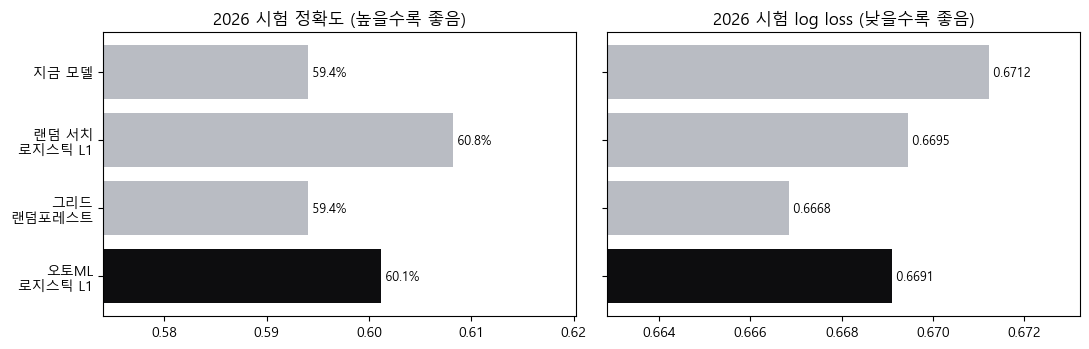

In [6]:
rnd = random_rep["finalists"][0]  # 랜덤 서치 추천 (06번)
grd = grid_rep["finalists"][0]    # 그리드 서치 추천
cands = [
    ("지금 모델 (로지스틱 C=1, L2)", grid_rep["current"], None),
    ("랜덤 서치 추천: 로지스틱 L1 C=0.03", rnd, rnd["mcnemar_p_vs_current"]),
    ("그리드 서치 추천: 랜덤포레스트", grd, grd["mcnemar_p_vs_current"]),
    ("오토머신러닝: 로지스틱 L1 C=0.031 (표준화 없음)", auto_rep["automl_final"], auto_rep["automl_final"]["mcnemar_p_vs_current"]),
]
summary = pd.DataFrame([{"모델": n, "2025 검증 log loss": f["val"]["log_loss"], "2026 시험 정확도": f["test"]["accuracy"],
                         "2026 시험 log loss": f["test"]["log_loss"], "지금 모델 대비 p값": p} for n, f, p in cands])
display(summary.style.format({"2025 검증 log loss": "{:.4f}", "2026 시험 정확도": "{:.1%}", "2026 시험 log loss": "{:.4f}",
                              "지금 모델 대비 p값": lambda v: "—" if v is None or pd.isna(v) else f"{v:.3f}"}).hide(axis="index"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
names = ["지금 모델", "랜덤 서치\n로지스틱 L1", "그리드\n랜덤포레스트", "오토ML\n로지스틱 L1"]
for ax, key, title, fmt in ((axes[0], "accuracy", "2026 시험 정확도 (높을수록 좋음)", "{:.1%}"),
                            (axes[1], "log_loss", "2026 시험 log loss (낮을수록 좋음)", "{:.4f}")):
    vals = [f["test"][key] for _, f, _ in cands]
    bars = ax.barh(names[::-1], vals[::-1], color=["#b9bcc3", "#b9bcc3", "#b9bcc3", "#0d0d0f"][::-1])
    for b, v in zip(bars, vals[::-1]):
        ax.text(b.get_width(), b.get_y() + b.get_height() / 2, " " + fmt.format(v), va="center", fontsize=9)
    ax.set_xlim(min(vals) - (0.02 if key == "accuracy" else 0.004), max(vals) + (0.012 if key == "accuracy" else 0.002))
    ax.set_title(title)
plt.tight_layout()
plt.show()

## 7. 정리

- **세 방법(랜덤 서치·그리드 서치·오토머신러닝) 모두 서로 비슷한 성적의 모델에 도착했어요.** 2026 시험 log loss는 0.667~0.671, 정확도는 59.4~60.8%예요.
- 그중 두 방법(랜덤 서치, 오토머신러닝)이 **따로따로 같은 답(L1 로지스틱 회귀, C ≈ 0.03)**을 골랐어요. 이 데이터에서는 "피처를 줄인 단순한 로지스틱 회귀"가 가장 믿을 만한 선택이라는 근거예요.
- 그리드 서치가 고른 랜덤포레스트는 검증에서 0.0004 앞섰지만 정확도는 지금 모델과 같고, 더 복잡하고 설명하기 어려워요.
- **어느 후보도 지금 모델(v0.2)보다 통계적으로 확실히 낫지는 않아요**(경기별 적중 McNemar p ≥ 0.16). 한 시즌 약 700경기로는 1%p 차이를 가려내기 어려워요.
- 그래서 이 노트북을 만들 때의 결론은 "2026 한 시즌으로는 지금 모델(v0.2)과 구별되지 않는다"였어요. 바꾼다면 L1 로지스틱 회귀(C=0.03)가 1순위였고요.
- 그 뒤 08번에서 시즌을 늘려 확인해 보니 이야기가 달라졌어요(아래 8번). 한 시즌으로 "차이가 없다"고 말할 수 없었던 것이지, 차이가 없었던 건 아니었어요.

## 8. 그 뒤 이야기 — 여러 시즌 시험으로 v0.3을 골랐어요 (08번)

이 노트북의 마지막 질문은 "1%p 남짓한 차이를 702경기로 가려낼 수 없다면, 어떻게 확인하지?"였어요. 답은 **경기 수를 정직하게 늘리는 것**이에요.
08번 노트북에서 2018~2026 시즌마다 "그 앞 시즌들로만 학습 → 그 시즌 예측"을 되풀이해 **6,328경기**를 모았어요(미래를 보지 않는 예측만 모아요). 후보와 고르는 규칙은 계산 전에 정해 뒀어요.
- 후보: v0.2 설정(L2, C = 1), L1(C = 0.03 — 랜덤 서치·오토머신러닝이 고른 값), **L1 + Elo 전력 점수**, 앙상블(L1 + 그리드 1등 랜덤포레스트 + 그리드 1등 XGBoost).
- 고르는 규칙: 개발 시즌 2018~2025의 합친 log loss가 가장 낮은 후보 → **L1 + Elo**.
- 2018~2026 정확도: L1 + Elo 57.9%, 앙상블 57.6%, L1 57.4%, v0.2 설정 56.5%. L1 + Elo는 v0.2 설정보다 유의하게 나았어요(McNemar p = 0.001). 그리드 서치가 고른 랜덤포레스트를 섞은 앙상블은 L1 + Elo를 넘지 못했어요.

그래서 지금 모델은 **v0.3 = 로지스틱 회귀 L1, C = 0.03 + Elo 피처(27개), 보정 없음**이에요. 이 노트북에서 두 방법이 따로 같은 답(L1, C ≈ 0.03)을 고른 것이 v0.3의 출발점이 됐어요.
정직하게 적어 둘 점: L1·앙상블의 설정은 2021~2025 교차검증으로 골랐으니, 08번에서 그 시즌들의 성적은 조금 유리해요. 그래서 08번은 설정 선택에 쓰지 않은 시즌(2018~2020, 2026)만 모은 성적도 함께 보여 줘요.

In [7]:
print(f"노트북 실행 시간: {time.time() - T0:.0f}초")

노트북 실행 시간: 37초
